# Assignment 3: Sampling Distributions and Estimation
Authored by Kristian M. P. Dashnaw (344849) & Katrine B. Aamand (344848) <br>
Based on assignment 3 description (https://rbrooksdk.github.io/STA1_26/assignments/assignment_03_sampling_and_estimation/)

## Table of Contents

1. **Part 1 — Sampling distributions and the CLT**
    - 1.1 Simulated Sample Means and Summary Table
    - 1.2 Sampling Distributions with Normal Overlays
    - 1.3 Tail Probability $P(\bar X>75)$: Simulation vs. CLT
    - 1.4 Smallest $n$ with $\operatorname{SE}(\bar X)\le6$ Minutes
    - 1.5 Running Mean and the Law of Large Numbers
    - CLT Scope Statement
2. **Part 2 — Estimating mean sensor error**
    - 2.1 Summary Statistics and Standard Error
    - 2.2 Histogram, QQ-Plot, and $t$-Interval Suitability
    - 2.3 95% $t$ Interval: Components and SciPy Verification
    - 2.4 90%, 95%, and 99% $t$ Intervals and Widths
    - 2.5 Sample-Size Planning for a 0.10 °C Margin of Error
    - 2.6 Percentile Bootstrap Interval
3. **Part 3 — Estimating a false-rejection proportion**
    - 3.1 Sample Size, False Rejections, and $\hat p$
    - 3.2 95% Wilson Interval
    - 3.3 95% Wald Interval and Comparison with Wilson
    - 3.4 90%, 95%, and 99% Wilson Intervals and Widths
    - 3.5 Sample-Size Planning for a 0.02 Margin of Error
4. **Part 4 — AI-Use and Conclusion**
    - AI-Use Statement
    - Overall Conclusion

## Working Notes

**How to present the work (from the assignment description):**

> Use executed code for every simulation, estimate, interval, table, and plot. Use Markdown for model statements, formulas, assumptions, coverage interpretations, and conclusions. Show requested interval components before verifying with a library function.

In [1]:
#Imports:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import probplot, t, bootstrap
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

# Load the data files:
print("\nSensor_Calibration.csv, first 5 rows:")
sensorCalibrationData_unmodified = pd.read_csv('data/assignment03_sensor_calibration.csv', delimiter = ',')
display(sensorCalibrationData_unmodified.head(5))

print("\n\nAccess_Control.csv, first 5 rows:")
accessControlData_unmodified = pd.read_csv('data/assignment03_access_control.csv', delimiter = ',')
display(accessControlData_unmodified.head(5))


Sensor_Calibration.csv, first 5 rows:


,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615




Access_Control.csv, first 5 rows:


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


<br><br><br>

---

<br><br>

## Part 1: Sampling distributions and the CLT

Restoration time in a service system is modelled as exponential with population mean and standard deviation $\mu=\sigma=60$ minutes. Use this known population model and NumPy's random generator with seed 2026 and at least 20,000 repetitions per sample size.

<br><br>

<br>

### 1.1 Simulate samples for $n=1,5,20,80$ and store their means. Create a table with $n$, theoretical mean, simulated mean of means, theoretical standard error $\sigma/\sqrt n$, and empirical standard deviation of the simulated means.

Each repetition draws one sample of $n$ independent restoration times from the known population model $X\sim\operatorname{Exp}(\lambda=1/60)$, which has $\mu=\sigma=60$ minutes, and stores its sample mean $\bar x$. Repeating this 20,000 times for each $n$ approximates the sampling distribution of $\bar X$.

By Theorem 5.1 in the course book, for i.i.d. observations

$$E[\bar X]=\mu \qquad \text{and} \qquad \operatorname{SE}(\bar X)=\frac{\sigma}{\sqrt n},$$

so the table compares these theoretical values with the mean and the standard deviation of the 20,000 simulated sample means.

In [2]:
# Katrine

# Known population model: exponential restoration times with mu = sigma = 60 minutes
mu = 60
sigma = 60
n_rep = 20_000
sample_sizes = (1, 5, 20, 80)
rng = np.random.default_rng(2026)

# For each n: draw n_rep samples of size n (one sample per row) and store the mean of each sample
sample_means = {}
for n in sample_sizes:
    samples = rng.exponential(scale=mu, size=(n_rep, n))   # NumPy's scale is the mean 1/lambda
    sample_means[n] = samples.mean(axis=1)

# Compare theory with simulation
rows = []
for n in sample_sizes:
    rows.append({"n": n,
                 "theoretical mean": mu,
                 "simulated mean of means": sample_means[n].mean(),
                 "theoretical SE": sigma / np.sqrt(n),
                 "empirical SD of means": sample_means[n].std(ddof=1)})
pd.DataFrame(rows).round(3)

,n,theoretical mean,simulated mean of means,theoretical SE,empirical SD of means
0,1,60,60.328,60.000,60.199
1,5,60,59.500,26.833,26.684
2,20,60,59.937,13.416,13.353
3,80,60,59.990,6.708,6.740


#### Findings
Centre: For every $n$ the simulated mean of the 20,000 sample means is close to the theoretical mean of 60 minutes (between 59.500 and 60.328 minutes). This matches $E[\bar X]=\mu$: the sample mean is centred on the population mean regardless of $n$.

Spread: The empirical standard deviation of the simulated means follows the theoretical standard error $\sigma/\sqrt n$ closely, e.g. 60.199 vs. 60.000 minutes for $n=1$ and 6.740 vs. 6.708 minutes for $n=80$. Going from $n=5$ to $n=20$ (four times as many observations) halves the standard error from 26.833 to 13.416 minutes, which shows the $1/\sqrt n$ rate.

The small differences between theory and simulation come from using a finite number of repetitions. More repetitions would make the simulated values more stable, but they would not change the standard error itself, which is determined by $n$, the number of observations in each sample.

<br><br>
### 1.2 Create one figure showing the four sampling distributions with density histograms and overlay $N(\mu,\sigma^2/n)$. Explain how centre, spread, and shape change and why the normal curve is an approximation for this non-normal population.

The histograms show the 20,000 simulated sample means from 1.1 for each $n$, on a density scale so that the total area is 1 and they can be compared with a density curve. The orange curve is the normal approximation from the central limit theorem (Theorem 5.4):

$$\bar X \approx N\!\left(\mu, \frac{\sigma^2}{n}\right)$$

The second parameter is the variance $\sigma^2/n$, so in SciPy the `scale` argument is the standard error $\sigma/\sqrt n$.

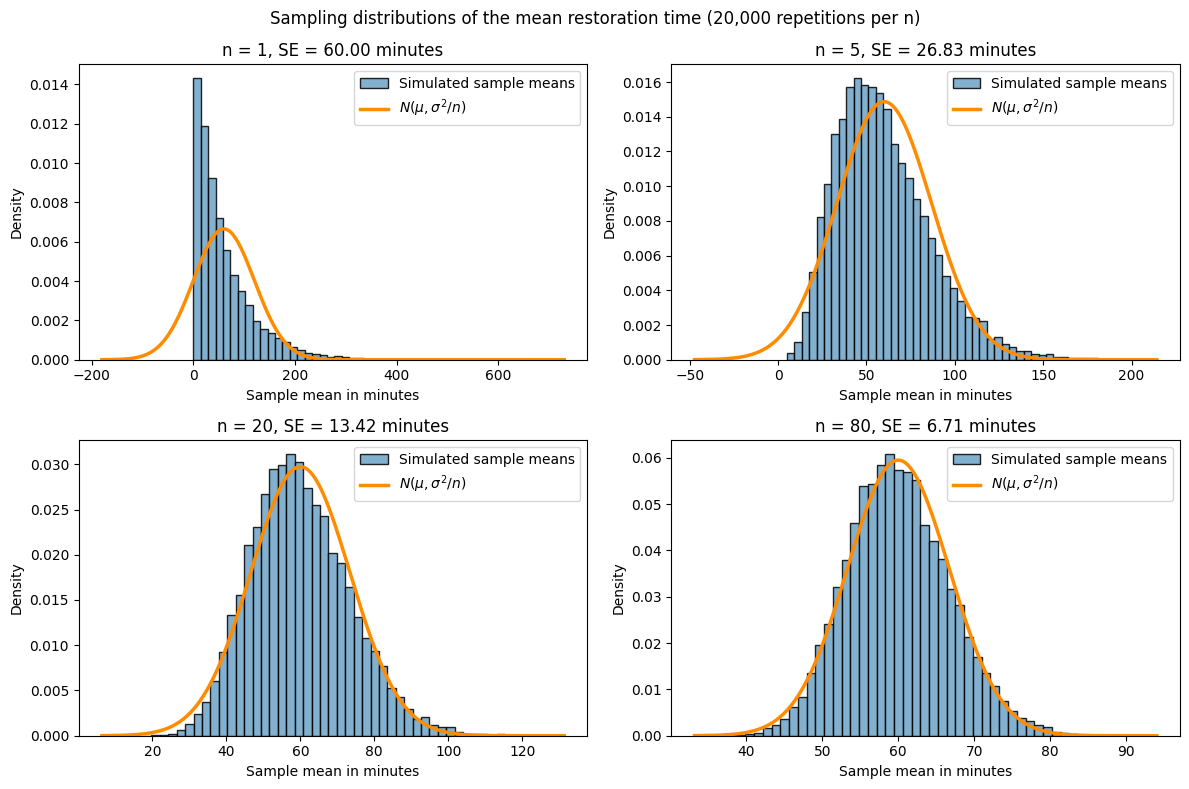

In [3]:
# Katrine

# One figure with the four simulated sampling distributions and the CLT normal curve N(mu, sigma^2/n)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, n in zip(axes.flat, sample_sizes):
    se_n = sigma / np.sqrt(n)
    ax.hist(sample_means[n], bins=50, density=True, color="#6CA2C6", edgecolor="black", alpha=0.85, label="Simulated sample means")
    x_grid = np.linspace(min(sample_means[n].min(), mu - 4 * se_n), sample_means[n].max(), 400)
    ax.plot(x_grid, stats.norm.pdf(x_grid, loc=mu, scale=se_n), color="#FF8C00", linewidth=2.5, label=r"$N(\mu, \sigma^2/n)$")
    ax.set(title=f"n = {n}, SE = {se_n:.2f} minutes", xlabel="Sample mean in minutes", ylabel="Density")
    ax.legend()
fig.suptitle("Sampling distributions of the mean restoration time (20,000 repetitions per n)")
plt.tight_layout()
plt.show()

#### Findings
Centre: The mean of each sampling distribution is close to $\mu=60$ minutes (see the table in 1.1), but for the skewed distributions the peak of the histogram lies to the left of 60: close to 0 minutes for $n=1$, around 45 minutes for $n=5$, around 57 minutes for $n=20$ and around 59 minutes for $n=80$. The long right tail pulls the mean to the right of the peak. The normal curve always peaks at 60, so the gap between the peak of the histogram and the peak of the curve is a visible sign of skew, and it shrinks as $n$ grows.

Spread: The spread shrinks as $n$ grows: the standard error goes from 60 minutes for $n=1$ to 6.71 minutes for $n=80$. Note that the x-axes differ between the panels; on a common axis the distribution for $n=80$ would be a narrow peak around 60.

Shape: For $n=1$ the histogram is simply the population itself: strongly right-skewed, starting at 0 with a long right tail. For $n=5$ the means are still clearly right-skewed, for $n=20$ the skew is mild, and for $n=80$ the histogram is close to the normal curve with only a slight right skew left. Averaging pulls in the extreme values, so the distribution of the mean becomes more symmetric as $n$ grows.

Why the normal curve is only an approximation: The population is exponential, not normal, so the exact result $\bar X\sim N(\mu,\sigma^2/n)$ for normal populations (Theorem 5.2) does not apply. The CLT only gives $\bar X\approx N(\mu,\sigma^2/n)$ for sufficiently large $n$, and how large $n$ must be depends on the population shape; a strongly skewed population like this one needs more observations. For $n=1$ the normal curve is clearly wrong: it places about 16% of its probability below 0 minutes, which is an impossible restoration time. Even for $n=5$ it places about 1.3% below 0 minutes, while the smallest simulated mean is about 5 minutes.

<br><br>
### 1.3 For $n=20$ and $n=80$, estimate $P(\bar X>75)$ by simulation and calculate the CLT approximation. Compare the values.

Simulation: the proportion of the 20,000 simulated sample means from 1.1 that are above 75 minutes.

CLT approximation: standardise with the standard error and use the upper tail of the normal distribution (SciPy's survival function `sf`):

$$P(\bar X>75)\approx P\!\left(Z>\frac{75-\mu}{\sigma/\sqrt n}\right)$$

For $n=20$: $z=\frac{75-60}{60/\sqrt{20}}=\frac{15}{13.416}=1.118$, and for $n=80$: $z=\frac{15}{6.708}=2.236$.

In [4]:
# Katrine

# Compare the simulated tail probability P(Xbar > 75) with the CLT approximation
threshold = 75
rows = []
for n in (20, 80):
    se_n = sigma / np.sqrt(n)
    z = (threshold - mu) / se_n
    p_clt = stats.norm.sf(threshold, loc=mu, scale=se_n)   # P(Xbar > 75) under N(mu, sigma^2/n)
    p_sim = np.mean(sample_means[n] > threshold)            # share of the simulated means above 75
    rows.append({"n": n, "SE": se_n, "z": z, "CLT approximation": p_clt, "simulated": p_sim, "simulated - CLT": p_sim - p_clt})
pd.DataFrame(rows).round(4)

,n,SE,z,CLT approximation,simulated,simulated - CLT
0,20,13.4164,1.1180,0.1318,0.1334,0.0016
1,80,6.7082,2.2361,0.0127,0.0186,0.0060


#### Findings
n = 20: The simulation gives $P(\bar X>75)\approx0.1334$ and the CLT approximation gives 0.1318. The two values are almost identical: about 13% of samples of 20 restoration times have a mean above 75 minutes.

n = 80: The simulation gives 0.0186 and the CLT approximation gives 0.0127. Both are small, because the standard error is halved and 75 minutes is now 2.24 standard errors above $\mu$. But here the simulated probability is about 1.5 times the CLT value.

Comparison: A larger $n$ makes the probability smaller, because the sample means are more concentrated around 60 minutes. The absolute differences between the two methods are small in both cases, but at $n=80$ the event lies further out in the right tail. This is where the remaining right skew of the sampling distribution matters most, since a right-skewed distribution has a heavier right tail than the symmetric normal curve. The simulated proportion is therefore the better description of this exponential model, while the CLT value is an approximation. The simulated values also contain simulation error, but with 20,000 repetitions it is only about $\sqrt{0.0186(1-0.0186)/20000}\approx0.001$ for $n=80$, so the difference of 0.0060 is not just simulation noise. For $n=20$ the difference of 0.0016 is within the simulation error of about 0.0024.

<br><br>
### 1.4 Find the smallest integer $n$ for which $\operatorname{SE}(\bar X)\le6$ minutes and verify it by simulation.


The standard error of the sample mean is $\operatorname{SE}(\bar X)=\sigma/\sqrt n$. Requiring it to be at most 6 minutes and solving for $n$ (as in Example 5.3 in the course book):

$$\frac{\sigma}{\sqrt n}\le 6 \quad\Longleftrightarrow\quad \sqrt n\ge\frac{60}{6}=10 \quad\Longleftrightarrow\quad n\ge\left(\frac{60}{6}\right)^2=100$$

Since $n$ must be an integer, the result is always rounded up (here it is already an integer). We check the neighbouring integer $n=99$, and then verify $n=100$ by simulating 20,000 samples of size 100.

In [5]:
# Katrine

# Smallest integer n with SE(Xbar) = sigma / sqrt(n) <= 6 minutes (always round up)
target_se = 6
n_required = int(np.ceil((sigma / target_se) ** 2))
print(f"smallest n = {n_required}")
for n in (n_required - 1, n_required):
    print(f"n = {n}: SE = {sigma / np.sqrt(n):.3f} minutes")

# Verify by simulation: 20,000 samples of size n_required from the same population model
means_required = rng.exponential(scale=mu, size=(n_rep, n_required)).mean(axis=1)
print(f"\nsimulated mean of means (n = {n_required})  = {means_required.mean():.3f} minutes")
print(f"empirical SD of means (n = {n_required})    = {means_required.std(ddof=1):.3f} minutes")

smallest n = 100
n = 99: SE = 6.030 minutes
n = 100: SE = 6.000 minutes

simulated mean of means (n = 100)  = 59.991 minutes
empirical SD of means (n = 100)    = 6.063 minutes


#### Findings
Smallest n: $n=100$ is the smallest integer with $\operatorname{SE}(\bar X)\le6$ minutes. With $n=100$ the standard error is exactly $60/\sqrt{100}=6.000$ minutes, while $n=99$ gives 6.030 minutes, which is above the target.

Simulation: For 20,000 simulated samples of 100 restoration times, the sample means are centred at 59.99 minutes and their standard deviation is 6.063 minutes. This is within about 1% of the theoretical 6 minutes, so the simulation confirms the calculation. The small difference is simulation variability from a finite number of repetitions. It is also the reason why a simulation cannot separate $n=99$ from $n=100$, so the exact requirement is found with the formula and the simulation is used as a check.

Since the standard error decreases at the rate $1/\sqrt n$, going from a standard error of 60 minutes for one observation to 6 minutes requires $10^2=100$ times as many observations.

<br><br>

### 1.5 Generate one sequence of 5,000 observations and plot its running mean. Explain the law of large numbers and how this plot differs from a sampling distribution.

Here we draw one single sequence of 5,000 restoration times from the same model and, after each new observation, recalculate the mean of all observations so far:

$$\bar x_k=\frac{1}{k}\sum_{i=1}^{k}x_i,\qquad k=1,\dots,5000$$

In the code, `np.cumsum` gives the running totals, which are divided by the number of observations so far.

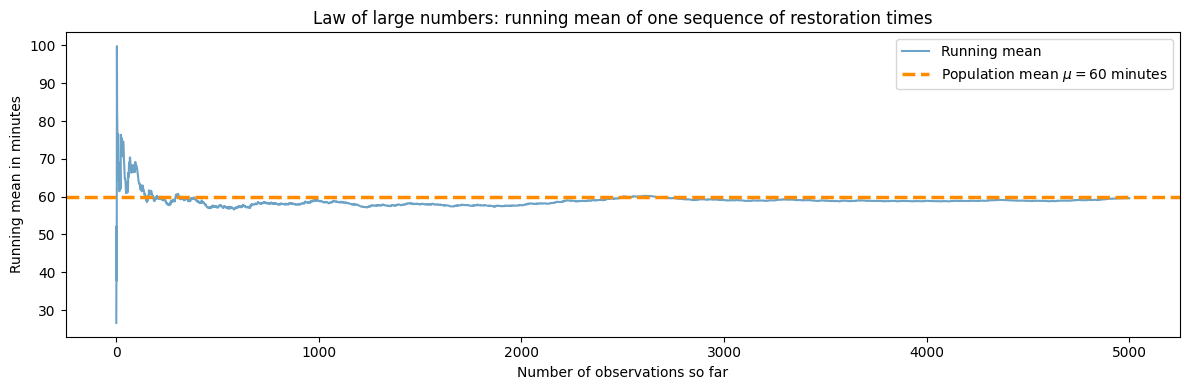

running mean after   10 observations = 76.56 minutes
running mean after  100 observations = 67.92 minutes
running mean after 1000 observations = 58.96 minutes
running mean after 5000 observations = 59.59 minutes


In [6]:
# Katrine

# One sequence of 5,000 restoration times and its running mean
n_sequence = 5_000
sequence = rng.exponential(scale=mu, size=n_sequence)
k = np.arange(1, n_sequence + 1) # number of observations so far
running_mean = np.cumsum(sequence) / k

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(k, running_mean, color="#6CA2C6", linewidth=1.5, label="Running mean")
ax.axhline(mu, color="#FF8C00", linestyle="--", linewidth=2.5, label=r"Population mean $\mu = 60$ minutes")
ax.set(title="Law of large numbers: running mean of one sequence of restoration times", xlabel="Number of observations so far", ylabel="Running mean in minutes")
ax.legend()
plt.tight_layout()
plt.show()

for checkpoint in (10, 100, 1000, 5000):
    print(f"running mean after {checkpoint:>4} observations = {running_mean[checkpoint - 1]:.2f} minutes")

#### Findings
Running mean: The running mean jumps around at first, because each new observation has a large influence on an average of only a few values (76.56 minutes after 10 observations). After about 300 observations it settles close to $\mu=60$ minutes (59.59 minutes after 5,000). It stays slightly below 60 for most of the sequence, because each point contains all earlier observations, so an early deviation is only diluted slowly. The size of the deviation fits the standard error, e.g. −0.41 minutes after 5,000 observations compared with $\operatorname{SE}=60/\sqrt{5000}=0.85$ minutes.

Law of large numbers: For i.i.d. observations, $P(|\bar X-\mu|\ge\varepsilon)\to0$ as $n\to\infty$ (Theorem 5.3): the mean of many observations is likely to be close to $\mu$. It does not say that $\bar x$ equals $\mu$, and it says nothing about the shape of the distribution of $\bar X$.

Difference from a sampling distribution: The plot follows one sequence where $n$ grows. A sampling distribution (1.2) consists of many independent samples of the same fixed size $n$. The running mean shows the LLN (concentration near $\mu$), while the histograms show the standard error and the CLT (spread and shape).

### CLT Scope Statement
The central limit theorem is a statement about sample means (and sums), not about individual observations. Individual restoration times are still exponential and right-skewed no matter how large $n$ is; only the distribution of $\bar X$ becomes approximately normal. The CLT also assumes i.i.d. observations from a stable population, so it does not repair dependence between observations, drift in the service process, or an unrepresentative sample. Our simulation only shows how the assumed exponential model behaves; it cannot establish that real restoration times follow this model.

<br><br><br>

---

<br>

## Part 2: Estimating mean sensor error

The file [assignment03_sensor_calibration.csv](./data/assignment03_sensor_calibration.csv) contains calibration errors from 64 independently selected temperature sensors. Error is `sensor reading − reference temperature`. Let $\mu$ be the population mean calibration error.

These are declared as celsius, as that is referenced in task 2.5.

<br><br>
### 2.1 Report $n$, $\bar x$, $s$, and the estimated standard error. Explain standard deviation versus standard error.

#### Defining the parameters from above:

##### $n$ is the sample size (i.e. number of observations in the sample)

<br>

##### $\bar x$ is the sample mean (i.e. observed estimate, as opposed to $\bar X$, which is a Random statistic (Estimator)). This is defined by definition 5.5 in the course book:

For observed values $x_{1},\ldots,x_{n}$, its realised value is

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_{i}.
$$

<br>

##### $s$ is the observed sample standard deviation (i.e. observed estimate, as opposed to $S$, which is a Random statistic (Estimator)). This is defined by definition 5.7 in the course book:

$$
s^{2}=\frac{1}{n-1}\sum_{i=1}^{n}\left(x_{i}-\bar{x}\right)^{2}.
$$

So the sample standard deviation is $S=\sqrt{S^{2}}$, with observed value $s$.

<br>

##### The standard error is given by the definition 5.6 in the course book as:

The **standard error** of a statistic is the standard deviation of its sampling distribution. For the sample mean,

$$\mathrm{SE}(\bar X) = \frac{\sigma}{\sqrt{n}}$$

If $\sigma$ is unknown, it is commonly estimated by

$$
\widehat{\mathrm{SE}}(\bar{X})=\frac{S}{\sqrt{n}}
$$



In [7]:
# Kristian
x = sensorCalibrationData_unmodified["calibration_error_c"].to_numpy()
n = x.size
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)

print(f"n = {n}")
print(f"estimate xbar  = {xbar:.3f} °C")
print(f"sample SD s    = {s:.3f} °C")
print(f"SE(Xbar)       = {se:.3f} °C")

n = 64
estimate xbar  = 0.188 °C
sample SD s    = 0.626 °C
SE(Xbar)       = 0.078 °C


#### Explaining Standard Deviation versus Standard Error
**The observed standard deviation** $s$ is a measure for the **variation among the individual observations**. It does not necessarily become smaller just because more data is collected, but instead settles closer to $\sigma$.

**The Standard Error** $\frac{S}{\sqrt{n}}$ is a measure for the **variation among means from repeated samples of size $n$**. It becomes smaller the more data is collected (at the rate of $\frac{1}{\sqrt{n}}$)

For this sample, this means that we use $s$ to measure how much the calibration errors vary from sensor to sensor, while the standard error describes how much the sample mean ($\bar x$) is estimated to vary if these observations were done again with 64 new sensors. Therefor, the standard error measures how precisely $\bar x$ estimates the population mean calibration error $\mu$.


<br><br>
### 2.2 Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears reasonable and why plots cannot establish independence.

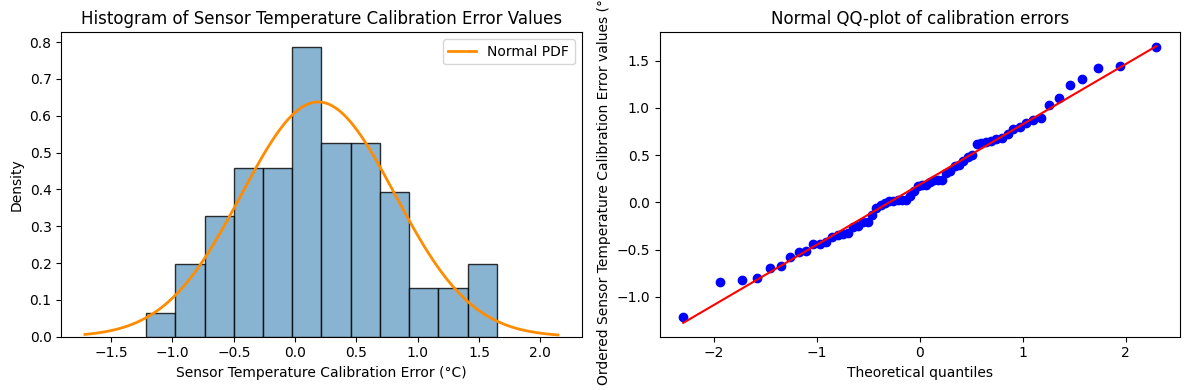

In [8]:
# Kristian

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(x.min()-0.5, x.max()+0.5, 200)
axes[0].hist(x, bins=12, density=True, edgecolor="black", color="#6CA2C6", alpha=0.8)
axes[0].plot(xs, stats.norm(loc=xbar, scale=s).pdf(xs), color="#FF8C00", lw=2, label="Normal PDF")
axes[0].set_title("Histogram of Sensor Temperature Calibration Error Values")
axes[0].set_xlabel("Sensor Temperature Calibration Error (°C)")
axes[0].set_ylabel("Density")
axes[0].legend()
probplot(x, plot=axes[1])
axes[1].set_title("Normal QQ-plot of calibration errors")
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Ordered Sensor Temperature Calibration Error values (°C)")
plt.tight_layout()
plt.show()

From chapter 6.3. in the course book (p. 102), we know that one-sample t-intervals are exact under i.i.d. (independent and identically distributed) normal sampling - and for non-normal populations it is commonly used as an approximation when:
1. Sample mean is approximately normal.
2. Sample standard deviation estimates the population spread adequately.
3. Additionally, the quality of the approximation is influenced negatively by:
    - Strong skew.
    - Heavy Tails.
    - Influential outliers.
    - Dependence and process drift.

#### Discussion: Is a one-sample t interval reasonable?
To evaluate whether a one-sample t interval is reasonable, we need to look at how well our sample aligns with the requirements for using t-intervals presented above.

- For the histogram we see that the data forms one primary "hump" and is roughly symmetric around its center. We also see that values are quite tight (i.e. there are no extreme values far from the rest of the values). This is also visible in the QQ-plot: neither end has isolated points far from the line, which means that there are no apparent outliers. Using the values from 2.1, the interval $\bar x \pm 3s = 0.188 \pm 3 \cdot 0.626 \approx [-1.69,\ 2.07]$ °C contains all observations. A normal distribution would contain 99.7% within 3 standard deviations of its mean; the histogram shows values from about $-1.2$ to $1.6$ °C.

- For the QQ plot we see that the dots (sample data) form an approximate straight line, with a slight wiggle near each end. For a completely normal distribution we should expect all values to line up close to a straight line, with only small random deviations. Here we see them on an approximately straight line. A trend showing curvature (up/down) across multiple values would be an indicator that the sample is not approximately normally distributed.

**Requirement 1: Is the sample mean approximately normal?**
We only have one sample and therefore only one $\bar x$, so this cannot be seen directly in the plots. Instead, we can use the central limit theorem, which says that for i.i.d. observations with finite variance, $\bar X \approx N\!\left(\mu, \frac{\sigma^2}{n}\right)$, with estimated standard error $s/\sqrt{n} = 0.078$ °C, that we computed in 2.1. How large $n$ must be, depends on the population shape: *"A symmetric, light-tailed population can produce an approximately normal mean for a modest n"* (course book, p. 89). The plots above show this type of shape, meaning that with $n = 64$ the CLT approximation appears to be good.

**Requirement 2: Does $s$ estimate the population spread adequately?**
Since $s$ is based on squared distances from the mean, a few extreme values or heavy tails would inflate it. In the QQ-plot, heavy tails would show as both ends bending away from the line (course book, p. 80). We see here that the ends only deviate slightly from the line, and no observations lie far from the rest. All observations also lie within $\bar x \pm 3s$ (see above). We therefore consider $s = 0.626$ °C a reasonable estimate of the population spread.

**Based on the above, a one-sample t interval seems reasonable** - of course under the assumption the observations are independent, which we elaborate upon in the paragraph below.

<br><br>

#### Discussion: Why plots cannot establish independence:
Plots do not say anything about how data was collected. It does not say if these sensors are all connected, are all located in the exact same measurement environment, etc. and if they potentially can influence each other. Consider the case where the sensor used to collect the reference temperature used to calibrate all the sensors in this sample was faulty - that would mean every sensor was not independent as they share the common reference sensor. Here, the assignment states that the sensors were *independently selected*, which is the basis for treating the observations as independent and for using $\widehat{\mathrm{SE}}(\bar X) = s/\sqrt{n}$. Here the plots help evaluate skew, heavy tails and outliers from point 3, but not dependence and drift.

<br><br>
### 2.3 Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard error, and margin of error. Verify it with SciPy and interpret both the interval and the 95% confidence level correctly.

The course book (6.3 page 101) defines the statistic T for an unknown population standard deviation (i.e. $\sigma$ is unknown), under normal sampling with:

$$
T = \frac{\bar{X} - \mu}{S / \sqrt{n}} \sim t_{n-1}
$$

For observed data, theorem 6.2 makes this definition:

$$
\bar{x} \pm t_{n-1,\, 1-\alpha/2} \frac{s}{\sqrt{n}}
$$

From the latter, we can therefor define the 95% t interval for a mean with an unknown $\sigma$, which is the case in this task, to be between endpoints defined by:

$$
\bar{x} \pm t_{64-1,\, 1-0.05/2} \frac{0.626}{\sqrt{64}} = 0.188 \pm t_{64-1,\, 0.975} \frac{0.626}{8}
$$

We could use a T-table to determine the t value of the 0.975 quantile of a Student t with 64-1 degrees of freedom - but the tables provided in this course have degrees of freedom of 60 as the nearest exact value, so we will instead compute it using t.ppf.

In [9]:
# Kristian
dof_t = n - 1
print(f"degrees of freedom                        = {dof_t}")

t_critical_value = t.ppf(0.975, dof_t)
print(f"t critical value w. {dof_t} degrees of freedom = {t_critical_value:.3f}")

print(f"standard error                            = {se:.3f} °C")

margin_of_error = t_critical_value * se
print(f"margin of error                           = {margin_of_error:.3f} °C")

confidence_interval_low_end = xbar - margin_of_error
confidence_interval_high_end = xbar + margin_of_error

print(f"95% t-interval                            = [{confidence_interval_low_end:.3f}, {confidence_interval_high_end:.3f}] °C")

# Checking with scipy:
# Note that this uses scale as the standard error (not as s) and we just pass the 0.95 directly.
confidence_interval_scipy = t.interval(0.95, dof_t, loc=xbar, scale=se)
print(f"SciPy check                               = [{confidence_interval_scipy[0]:.3f}, {confidence_interval_scipy[1]:.3f}] °C")

degrees of freedom                        = 63
t critical value w. 63 degrees of freedom = 1.998
standard error                            = 0.078 °C
margin of error                           = 0.156 °C
95% t-interval                            = [0.032, 0.345] °C
SciPy check                               = [0.032, 0.345] °C


The SciPy check aligns with the calculated result.

**Interpreting the interval:** We have 64 sensors in our sample. We found that the 95% t interval for the population mean calibration error $\mu$ is $[0.032, 0.345]$ °C.
This is the interval within which *mean* error of *all sensors* will plausibly fall within (i.e. a range of plausible values for $\mu$). This is *not* where individual sensors will plausibly fall within - which was -1.2 to 1.6 °C as seen on the histogram in 2.2.

**Interpreting the 95% confidence level:** $\mu$ for the population is an unknown, but fixed, number. It will either lie within $[0.032, 0.345]$ °C, or not. It is the interval itself (endpoints) that change, depending on the sample used in the specific procedure (Course book, p. 99). Based on what we have computed here, we cannot say that $\mu$ lies in the identified interval with 0.95 probability. What this describes is the *procedure*, i.e. if we repeat the study many times using new samples of 64 sensors enough times we will end up seeing that about 95% of the intervals we construct using this approach, will contain $\mu$, given the assumptions discussed in 2.2.

<br><br>
### 2.4 Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence–precision trade-off.

In [10]:
# Kristian
# 90% Confidence interval
print("Computing the 90% confidence interval")
t_critical_value_90 = t.ppf(1 - (0.1/2), dof_t)
print(f"t critical t_({dof_t}, 0.95)                   = {t_critical_value_90:.3f}")

margin_of_error_t_90 = t_critical_value_90 * se
print(f"margin of error (t 0.90)                  = {margin_of_error_t_90:.3f} °C")

confidence_interval_t_90_low_end = xbar - margin_of_error_t_90
confidence_interval_t_90_high_end = xbar + margin_of_error_t_90

print(f"90% t-interval                            = [{confidence_interval_t_90_low_end:.3f}, {confidence_interval_t_90_high_end:.3f}] °C")

# Checking with scipy:
# Note that this uses scale as the standard error (not as s) and we just pass the 0.90 directly.
confidence_interval_scipy = t.interval(0.90, dof_t, loc=xbar, scale=se)
print(f"SciPy check (t 0.90)                      = [{confidence_interval_scipy[0]:.3f}, {confidence_interval_scipy[1]:.3f}] °C")

# 95% Confidence interval
# Already computed in 2.3.
print("\nThe 95% confidence interval (from 2.3)")
print(f"95% t-interval                            = [{confidence_interval_low_end:.3f}, {confidence_interval_high_end:.3f}] °C")


# 99% Confidence interval
print("\nComputing the 99% confidence interval")
t_critical_value_99 = t.ppf(1 - (0.01/2), dof_t)
print(f"t critical t_({dof_t}, 0.995)                  = {t_critical_value_99:.3f}")

margin_of_error_t_99 = t_critical_value_99 * se
print(f"margin of error (t 0.99)                  = {margin_of_error_t_99:.3f} °C")

confidence_interval_t_99_low_end = xbar - margin_of_error_t_99
confidence_interval_t_99_high_end = xbar + margin_of_error_t_99

print(f"99% t-interval                            = [{confidence_interval_t_99_low_end:.3f}, {confidence_interval_t_99_high_end:.3f}] °C")

# Checking with scipy:
# Note that this uses scale as the standard error (not as s) and we just pass the 0.99 directly.
confidence_interval_scipy = t.interval(0.99, dof_t, loc=xbar, scale=se)
print(f"SciPy check (t 0.99)                      = [{confidence_interval_scipy[0]:.3f}, {confidence_interval_scipy[1]:.3f}] °C\n\n")

# With the above calculations made, I had Claude Opus generate the following table - recalculating values as needed, since this can be easily verified against the value above.
print(f"Combining these into a table:")
rows = []
for level in (0.90, 0.95, 0.99):
    q = 1 - (1 - level) / 2                 # 0.95, 0.975, 0.995
    t_crit = t.ppf(q, dof_t)
    moe = t_crit * se
    lo, hi = xbar - moe, xbar + moe
    rows.append({"confidence level": f"{level:.0%}", "quantile q": q,
                 "t_(63, q)": t_crit, "margin of error (°C)": moe,
                 "lower (°C)": lo, "upper (°C)": hi, "width (°C)": 2 * moe})
pd.DataFrame(rows).round(3)

Computing the 90% confidence interval
t critical t_(63, 0.95)                   = 1.669
margin of error (t 0.90)                  = 0.131 °C
90% t-interval                            = [0.058, 0.319] °C
SciPy check (t 0.90)                      = [0.058, 0.319] °C

The 95% confidence interval (from 2.3)
95% t-interval                            = [0.032, 0.345] °C

Computing the 99% confidence interval
t critical t_(63, 0.995)                  = 2.656
margin of error (t 0.99)                  = 0.208 °C
99% t-interval                            = [-0.019, 0.396] °C
SciPy check (t 0.99)                      = [-0.019, 0.396] °C


Combining these into a table:


,confidence level,quantile q,"t_(63, q)",margin of error (°C),lower (°C),upper (°C),width (°C)
0,90%,0.950,1.669,0.131,0.058,0.319,0.261
1,95%,0.975,1.998,0.156,0.032,0.345,0.313
2,99%,0.995,2.656,0.208,-0.019,0.396,0.416


We see clearly that as the confidence level increases (going from 90% to 99%), the width of the interval also increases. A higher confidence level requires the procedure to catch the fixed, unknown $\mu$ in a larger share of repeated samples (measured over many repetitions of the procedure) - so the interval must be wider.

We see this in the formula itself, where the t critical value grows from 1.669 at 90% confidence to 2.656 at 99% confidence. But the Standard Error $se$ remains the same across all the computed confidence intervals. Therefor the margin of error increases as confidence level increases (since moe = t_critical_value * se), which in turn applies a wider spread to the endpoints of the interval (since endpoints = xbar +/- moe).

As we demand a higher confidence level (i.e. a procedure that catches $\mu$ more often), we must accept a lower precision, since the interval itself becomes wider.

If we wanted both higher confidence **and** higher precision, we would need to add more independent observations as that would decrease the standard error $s/\sqrt{n}$.

<br><br>
### 2.5 Using $s$ as a planning value and the normal critical value, find the smallest approximate sample size for a 95% margin of error no larger than $0.10\ ^\circ\mathrm C$.

The Course Book chapter 6.3 p. 102, defines that if we have either $\sigma$ or a credible planning value, the margin of error of a two-sided z-interval is given by:

$$
E = z_{1-\alpha/2} \frac{\sigma}{\sqrt{n}}
$$

Solving for $n$ gives

$$
n \geq \left( \frac{z_{1-\alpha/2} \sigma}{E} \right)^2
$$

Since we don't know $\sigma$ but we do know that $s$ is our planning value, we can use $s$ in place of $\sigma$.

The course book makes it clear that we must always **round up** when calculating the value, because rounding down would exceed the target margin of error.

The value we are missing, is the $z_{1-0.05/2}$, or $z_{0.975}$.

We read this from our z-table to be $z_{0.975} = 1.960$.

In [11]:
# Kristian
# s was also calculated in 2.1
z_normal_critical_value = 1.960
target_margin_of_error = 0.1
s = x.std(ddof=1)

smallest_sample_size = ((z_normal_critical_value * s)/target_margin_of_error) ** 2

print(f"Smallest approximate sample size for a 95% margin of error, no larger than 0.10 °C sensor calibration temperature error:\n    {smallest_sample_size:.3f} sensors")

Smallest approximate sample size for a 95% margin of error, no larger than 0.10 °C sensor calibration temperature error:
    150.421 sensors


While the precise number of observations required is a decimal value, we must **round up** to avoid exceeding the target margin of error - since more independent observations increases precision as discussed in 2.4.

The smallest approximate sample size for a 95% margin of error no larger than 0.10 °C, is therefor **151 independent observations**.

<br><br>

### 2.6 With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval. Compare it with the $t$ interval and state what the comparison cannot validate.

By "percentile bootstrap interval", we here assume the task asks for a 95% percentile bootstrap interval, that we then compare with the 95% t interval.

A Bootstrap sample is drawn with replacement from the actually observed values.

In [12]:
# Kristian
boot = bootstrap(
    (x,),
    np.mean,
    confidence_level=0.95,
    n_resamples=10000,
    method="percentile",
    random_state=np.random.default_rng(2026),
)
print(f"bootstrap 95% percentile interval = [{boot.confidence_interval.low:.3f}, {boot.confidence_interval.high:.3f}] °C")
print(f"95% t-interval (from 2.3)         = [{confidence_interval_low_end:.3f}, {confidence_interval_high_end:.3f}] °C")


bootstrap 95% percentile interval = [0.041, 0.341] °C
95% t-interval (from 2.3)         = [0.032, 0.345] °C


We see that the 95% percentile bootstrap interval lies quite close to the 95% t-interval.

Width of the 95% percentile interval is $0.341 - 0.041 = 0.300$ °C, while the width of the 95% t-interval is $0.345 - 0.032 = 0.313$ °C.

That's a minor difference of $0.013$ °C.

Since the bootstrap approximates the sampling variation by resampling the observed data instead of using the $t$ distribution (course book, ch 6.5, p. 106), it acts as a computational check of our $t$ interval. The very minor difference indicates that the $t$ interval is consistent with the sampling variation seen in our own data. The bootstrap does **not** create new information, beyond what is already observed. It cannot be used to validate or repair bias in the data or lack of independence in the observations - so it is affected by these same limitations as the t-intervals themselves. Both intervals, after all, come from the same 64 observations - so they would be affected by the same data collection issues.

<br><br><br>

---

<br>

## Part 3: Estimating a false-rejection proportion

The file [assignment03_access_control.csv](./data/assignment03_access_control.csv) contains 240 independently staged legitimate login attempts. `false_reject` equals 1 when a legitimate attempt was rejected and 0 otherwise. Let $p$ be the population false-rejection probability under the test conditions.

<br><br>
### 3.1 Report $n$, the number of false rejections $x$, and $\hat p$. Explain why $\hat p$ is also the sample mean of a binary variable.

`false_reject` is a binary (0/1) variable: $y_i=1$ if legitimate attempt $i$ was rejected and $y_i=0$ otherwise. We report the number of attempts $n$, the number of false rejections $x=\sum y_i$, and the sample proportion

$$\hat p=\frac{x}{n}$$

In [13]:
# Katrine

# The binary false_reject variable: 1 = legitimate attempt rejected, 0 = accepted
false_rejections = accessControlData_unmodified["false_reject"].to_numpy()
print(f"values in the column = {np.unique(false_rejections)}")

n_false_rejections = false_rejections.size
x_false_rejections = int(false_rejections.sum())
p_hat_false_rejections = x_false_rejections / n_false_rejections

print(f"n                    = {n_false_rejections}")
print(f"x                    = {x_false_rejections}")
print(f"p_hat = x / n        = {p_hat_false_rejections:.4f}")
print(f"mean of the 0/1 data = {false_rejections.mean():.4f}")

values in the column = [0 1]
n                    = 240
x                    = 20
p_hat = x / n        = 0.0833
mean of the 0/1 data = 0.0833


#### Findings
Results: The sample contains $n=240$ legitimate login attempts, of which $x=20$ were falsely rejected, so $\hat p=20/240=0.0833$. About 8.3% of the legitimate attempts in the sample were rejected.

Why $\hat p$ is a sample mean: Each attempt is coded as $y_i=1$ (rejected) or $y_i=0$ (accepted). When the values are added up, the 0s contribute nothing and each 1 contributes one, so the sum is exactly the number of false rejections, $\sum y_i=x$. Therefore

$$\hat p=\frac{x}{n}=\frac{1}{n}\sum_{i=1}^{n}y_i=\bar y,$$

which is the sample mean (Definition 5.5) applied to the 0/1 variable. The code confirms this, since $x/n$ and the mean of the column both give 0.0833. Because $\hat p$ is the sample mean of i.i.d. Bernoulli observations with $P(Y_i=1)=p$, the results for sample means also apply: $E[\hat p]=p$, so $\hat p$ is an unbiased estimator of $p$, and $\operatorname{SE}(\hat p)=\sqrt{p(1-p)/n}$.

<br><br>
### 3.2 Construct and interpret a 95% Wilson interval for $p$ with statsmodels. State the population and parameter clearly.

Population: all legitimate login attempts made under the same test conditions as the staged attempts. The 240 attempts are a sample from this population.

Parameter: $p$ is the probability that a legitimate login attempt is falsely rejected under these test conditions, i.e. the long-run false-rejection rate. $p$ is fixed but unknown, and $\hat p=0.0833$ from 3.1 is our estimate of it.

The Wilson interval is computed with statsmodels' `proportion_confint`, using `count` $=x$, `nobs` $=n$, `alpha=0.05` for 95% confidence and `method="wilson"`.

In [14]:
# Katrine

# 95% Wilson interval for p with statsmodels
wilson_95_low, wilson_95_high = proportion_confint(x_false_rejections, n_false_rejections, alpha=0.05, method="wilson")

print(f"p_hat                 = {p_hat_false_rejections:.4f}")
print(f"95% Wilson interval   = [{wilson_95_low:.4f}, {wilson_95_high:.4f}]")
print(f"width                 = {wilson_95_high - wilson_95_low:.4f}")
print(f"distance below p_hat  = {p_hat_false_rejections - wilson_95_low:.4f}")
print(f"distance above p_hat  = {wilson_95_high - p_hat_false_rejections:.4f}")

p_hat                 = 0.0833
95% Wilson interval   = [0.0546, 0.1252]
width                 = 0.0706
distance below p_hat  = 0.0287
distance above p_hat  = 0.0419


#### Findings
Interval: The 95% Wilson interval for $p$ is $[0.055, 0.125]$. Under the test conditions, false-rejection probabilities from about 5.5% to 12.5% are plausible given the 20 rejections observed among 240 legitimate attempts.

Asymmetry: The interval is not centred at $\hat p=0.083$; it extends 0.029 below and 0.042 above $\hat p$. Since $\hat p$ is close to 0, there is more room for uncertainty upwards than downwards, and the Wilson interval reflects this while staying inside $[0,1]$.

Interpreting the 95%: $p$ is a fixed number, so the realised interval $[0.055, 0.125]$ either contains $p$ or it does not, and we cannot say that $p$ lies in it with probability 0.95. The 95% describes the procedure: if the test with 240 independent legitimate attempts were repeated many times, and a Wilson interval were constructed each time, approximately 95% of these intervals would contain $p$.

Scope: The interval concerns the false-rejection probability under the staged test conditions. It does not directly describe real users under other conditions, and it relies on the attempts being independent with a stable $p$.

<br><br><br>
### 3.3 Calculate the 95% Wald interval from its formula. Compare it with Wilson and explain why Wilson is the preferred default.

The Wald interval (Definition 6.6) follows the general pattern estimate ± critical value × standard error:

$$\hat p \pm z_{1-\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}$$

For 95% confidence, $\alpha=0.05$ and $z_{0.975}=1.960$. The estimated standard error replaces the unknown $p$ with $\hat p$. We compute each component, check the result with statsmodels (`method="normal"` is the Wald interval) and compare it with the Wilson interval from 3.2.

In [15]:
# Katrine

# 95% Wald interval from its formula: p_hat +/- z * sqrt(p_hat * (1 - p_hat) / n)
z_975 = stats.norm.ppf(0.975)
se_p_hat = np.sqrt(p_hat_false_rejections * (1 - p_hat_false_rejections) / n_false_rejections)
margin_of_error_wald = z_975 * se_p_hat
wald_95_low = p_hat_false_rejections - margin_of_error_wald
wald_95_high = p_hat_false_rejections + margin_of_error_wald

print(f"z critical value     = {z_975:.3f}")
print(f"estimated SE(p_hat)  = {se_p_hat:.4f}")
print(f"margin of error      = {margin_of_error_wald:.4f}")
print(f"95% Wald interval    = [{wald_95_low:.4f}, {wald_95_high:.4f}]")

# Check with statsmodels ("normal" is the Wald interval)
wald_check_low, wald_check_high = proportion_confint(x_false_rejections, n_false_rejections, alpha=0.05, method="normal")
print(f"statsmodels check    = [{wald_check_low:.4f}, {wald_check_high:.4f}]")

# Expected counts used as a rough diagnostic for the normal approximation
print(f"\nn * p_hat = {n_false_rejections * p_hat_false_rejections:.0f}, n * (1 - p_hat) = {n_false_rejections * (1 - p_hat_false_rejections):.0f}\n")

# Wald vs. Wilson (from 3.2)
comparison = pd.DataFrame([
    {"method": "Wald", "lower": wald_95_low, "upper": wald_95_high, "width": wald_95_high - wald_95_low,
     "below p_hat": p_hat_false_rejections - wald_95_low, "above p_hat": wald_95_high - p_hat_false_rejections},
    {"method": "Wilson", "lower": wilson_95_low, "upper": wilson_95_high, "width": wilson_95_high - wilson_95_low,
     "below p_hat": p_hat_false_rejections - wilson_95_low, "above p_hat": wilson_95_high - p_hat_false_rejections},
])
comparison.round(4)

z critical value     = 1.960
estimated SE(p_hat)  = 0.0178
margin of error      = 0.0350
95% Wald interval    = [0.0484, 0.1183]
statsmodels check    = [0.0484, 0.1183]

n * p_hat = 20, n * (1 - p_hat) = 220



,method,lower,upper,width,below p_hat,above p_hat
0,Wald,0.0484,0.1183,0.0699,0.0350,0.0350
1,Wilson,0.0546,0.1252,0.0706,0.0287,0.0419


#### Findings
Wald interval: With $\hat p=0.0833$, $\widehat{\operatorname{SE}}(\hat p)=0.0178$ and $z_{0.975}=1.960$, the margin of error is $1.960\cdot0.0178=0.035$, so the 95% Wald interval is $[0.048, 0.118]$. The statsmodels check gives the same result.

Comparison with Wilson: The two intervals have almost the same width (0.070 vs. 0.071), but they are placed differently. The Wald interval is symmetric around $\hat p$ (0.035 on both sides), while the Wilson interval $[0.055, 0.125]$ is shifted upwards. The Wald interval therefore has a lower upper limit (11.8% vs. 12.5%), so it makes the highest plausible false-rejection rates look smaller than the Wilson interval does. In this dataset the difference is small, because the sample is fairly large and contains both enough rejections and enough accepted attempts ($n\hat p=20$ and $n(1-\hat p)=220$, both above the rough guideline of 10).

Why Wilson is the preferred default: The Wald interval relies directly on the normal approximation of $\hat p$ and on plugging $\hat p$ into the standard error. For small samples or proportions near 0 or 1 this works poorly: the interval can understate the uncertainty, so its actual coverage is lower than the stated 95%, and its endpoints can fall outside $[0,1]$, e.g. a negative lower limit. In the extreme case of 0 observed rejections, $\hat p=0$ gives an estimated standard error of 0, and the Wald interval collapses to $[0,0]$ as if there were no uncertainty. The Wilson interval generally has more reliable coverage, can be asymmetric, and always stays within $[0,1]$. Since false rejections are a fairly rare event, Wilson is the safer choice and is used as the primary interval for $p$ in this report.

<br><br>
### 3.4 Create a table of 90%, 95%, and 99% Wilson intervals and widths.

From the course book (chapter 6.4 p. 104), we have that a wilson interval given by this definition:

For $z = z_{1-\alpha/2}$, the Wilson interval is

$$
\frac{\hat{p} + \dfrac{z^{2}}{2n} \pm z\sqrt{\dfrac{\hat{p}(1-\hat{p})}{n} + \dfrac{z^{2}}{4n^{2}}}}{1 + \dfrac{z^{2}}{n}}.
$$

In [16]:
# Kristian
false_rejections = accessControlData_unmodified["false_reject"].to_numpy()
n_false_rejections = false_rejections.size                 # number of attempts
x_false_rejections = int(false_rejections.sum())           # number of false rejections (count of 1s)
p_hat_false_rejections = x_false_rejections / n_false_rejections

# Arguments used by proportion_confint(count, nobs, alpha, method):
# count – number of successes. In this case, the number of false rejections within the set of all login attempts.
# nobs – total number of trials. In this case, the number of all login attempts.
# alpha – Significance level to use. The method returns an interval with confidence level 1 - alpha, so here we just provide the difference at the endpoints (i.e. alpha/2 outside each endpoint; 0.05 for 95%).
# method – We use wilson, as defined in this task description.
rows = []
for level in (0.90, 0.95, 0.99):
    a = 1 - level
    z = stats.norm.ppf(1 - a/2)
    lo, hi = proportion_confint(
        x_false_rejections,
        n_false_rejections,
        alpha=a,
        method="wilson"
    )

    rows.append({"confidence level": f"{level:.0%}",
                 "wilson lower endpoint": lo,
                 "wilson upper endpoint": hi,
                 "width": hi - lo,
                 "z": z,
                 "p_hat": p_hat_false_rejections,
                 "wilson centre": (p_hat_false_rejections + z**2 / (2*n_false_rejections)) / (1 + z**2 / n_false_rejections),
                 "below p_hat": p_hat_false_rejections - lo,
                 "above p_hat": hi - p_hat_false_rejections})

pd.DataFrame(rows).round(3)

,confidence level,wilson lower endpoint,wilson upper endpoint,width,z,p_hat,wilson centre,below p_hat,above p_hat
0,90%,0.058,0.118,0.059,1.645,0.083,0.088,0.025,0.034
1,95%,0.055,0.125,0.071,1.960,0.083,0.090,0.029,0.042
2,99%,0.048,0.141,0.093,2.576,0.083,0.095,0.035,0.058


Similar to 2.4, we see with the wilson intervals that their width (from 0.059 to 0.093) becomes larger as the confidence level increases (from 90% to 99%). Specifically for wilson, all lower and upper endpoints are bound within [0, 1]. We see that while confidence level increases the precision goes down. Another point of observation is that the wilson endpoints don't change symmetrically in both ends (as they did with t intervals shown in 2.4), instead they change asymmetrically around the $\hat p$ value (approx. 0.083 from 3.1). From 90% to 99% confidence level increase, we see the lower endpoint decreasing by $0.058 - 0.048 = 0.010$ while the upper endpoint increases by $0.141 - 0.118 = 0.023$ - more than double of the lower endpoint. Why this happens is because the wilson interval is not centered at $\hat p$, but instead centered at $\left(\hat p + \frac{z^2}{2n}\right) / \left(1 + \frac{z^2}{n}\right)$ (from the formula provided above). This centre moves towards 0.5 as $z$ increases - and we see this in the table above where "wilson centre" moves from 0.088 to 0.095 as the confidence level increases and $z$ increases. Consequently, this asymmetric behavior causes the interval to expand more upwards than downwards. Compared to Wald, which theoretically can go below 0, this shows that wilson is useful for practical work (where negative probabilities are impossible).

<br><br>
### 3.5 Estimate the sample size for a 95% margin of error no larger than 0.02 using first $p=0.5$ and then the observed $\hat p$. Round up and explain the difference.

The Course Book chapter 6.4 p. 105, defines that if we have the approximate margin of error $E$, given by:

$$
E = z_{1-\alpha/2} \sqrt{\frac{p(1-p)}{n}},
$$

The planning requirement is:

$$
n \geq \frac{z_{1-\alpha/2}^{2}\, p(1-p)}{E^{2}}.
$$

We know that:
* $z_{0.975} = 1.960$
* $E = 0.02$
* $p = 0.5$

Using these, we can use the formula for n-above.

In [17]:
# Kristian
# Shared variables:
z_975 = 1.960
E = 0.02

# Estimating sample size when p = 0.5:
p = 0.5
n_p = ((z_975 ** 2) * p * (1 - p)) / (E ** 2)

# Estimating sample size when using p_hat = 0.083 (as shown in 3.4):
p_hat = x_false_rejections / n_false_rejections
n_p_hat = ((z_975 ** 2) * p_hat * (1 - p_hat)) / (E ** 2)

print(f"Min. required sample size with p = 0.5 is                  {n_p}")
print(f"Min. required sample size with p = {p_hat} is  {n_p_hat}")

Min. required sample size with p = 0.5 is                  2400.9999999999995
Min. required sample size with p = 0.08333333333333333 is  733.6388888888887


Using a 95% z-score and aiming for a margin of error of no more than 0.02, we find that **if p is 0.5** we will need **2401 observations** in our sample. **If we use p_hat**, we will need **734 observations** in our sample.

The difference in required sample sizes to reach the same margin of error, is about a factor of 3 when using $p = 0.5$ compared to $p = \hat p$. Thus, we see that the determining factor - when no other variables change - is $p \cdot ( 1 - p)$. Used in the formula, the product of this is largest at $p = 0.5$, because $p \cdot ( 1 - p)$ will be largest when $0.5 \cdot (1 - 0.5) = 0.25$. In that term, using either $p = 0.49$ or $p = 0.51$ gives 0.2499. As such, the worst case min. sample size will be given by $p = 0.5$.

On the other hand, if we know that $\hat p$ is a credible planning value (i.e. we can reasonably trust that p is $\hat p$ or smaller), then we see that using that allows us to settle for about a third of the observations as would have been required under the conservative estimate. Planning values can come from a previous study, a pilot sample, engineering specifications or simply by using a conservative planning value. This exercise itself could work as a pilot sample. Of course the attempts must be independent and made under the same, stable test conditions as the planned study, otherwise bias and drift can influence the results without this being visible from the numbers alone.

<br><br><br>

---

<br>

## Part 4: AI-Use and Conclusion
### AI-use
> State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient. If AI produced most of the code or text, state this honestly.

#### In part 1 - Claude Opus 5.5
`Assigned to: Katrine`
- AI was used as a sparring partner, and asked to elaborate and explaining principles
- AI was used to help with LaTex syntax, spellchecking and feedback on textual elements and code

##### What changed/got rejected:
- Text was adjusted based on the feedback
- Improved code

##### How we checked that the final work was correct:
- AI reviewed after corrections and statements where held checked
- Used the book and session materials for referencing
<br><br>

#### In part 2 - Claude Opus 5.5
`Assigned to: Kristian`
- Tasks were solved manually first, using the course tutorials, notes and course book as reference.
- AI was used as a sparring partner - asked to elaborate and help explain principles and concepts.
- It was used as a reviewer, being fed the initial solved versions of the tasks and asked to provide concrete feedback on the solutions.
- It was also used to help with the markdown latex syntax for math formulas.

##### What changed/got rejected:
- Textual discussions and interpretations were adjusted based on the provided feedback. Certain points were made clearer.
- I initially calculated 2.4 by "hand" and wrote the table in markdown. The AI reviewer rightfully pointed out that the assignment states that tables should be generated by code - so I had it generate the table in code.
- In 2.5 I mistakenly used the t-critical value in place of the z-value, despite the text asking for the normal critical value (z). AI review caught it, so I got the chance to change that.

##### How we checked that the final work was correct:
- SciPy's built-in functions were used to check the work.
- AI was also asked to check the results we computed - although not 100% reliable for such a task, the intent was to get the feedback in case the AI by chance identified an issue in the computed results.
<br><br>

#### In part 3 - Claude Opus 5.5
`Assigned to: Katrine & Kristian`
- Since 3.1 - 3.3 was assigned to Katrine, and 3.4 - 3.5 was assigned to Kristian, AI was used to enable parallel work on each assigned tasks. Kristian used AI to solve the entirety of 3.1 - 3.3 in order to have the basis in place to work on 3.4 - 3.5. The AI solutions were then removed and replaced with the actual solutions produced by Katrine. This approach enabled us to work around the traditional dilemma of "I can't start working on xx before yy is ready".
- AI was used as a sparring partner, and asked to elaborate and explain principles

##### What changed/got rejected:
- In 3.1-3.3, wording and code was improved
- In 3.4 added z, p_hat, wilson centre, below/above p_hat to shown table, to help explain the usefulness of the comparison of wilson between different confidence levels.

##### How we checked that the final work was correct:
- Compared to relevant sections from the course book (explanations and formulas).
- Used library functions to check the work.
- in part 3.1-3.3 AI also reviewed
<br><br>

_____________

### Overall conclusion
> Write approximately 150–250 words explaining how sample size and sampling variability affect sample means, standard errors, and confidence-interval precision. Report the two parameter estimates with uncertainty and state one design limitation for each study.
>
> Only use Sessions 5–6. Do not perform hypothesis tests or use methods from later sessions.

**Part 1 (simulation)**
The simulated sample means stayed centred at $\mu=60$ minutes, while their sampling variability, the standard error $\sigma/\sqrt n$, fell from 60 minutes ($n=1$) to 6.71 minutes ($n=80$). Since a margin of error is a critical value times the standard error, interval precision improves with $n$, but only at a square-root rate.

**Study 2**
- **Parameter:** $\mu$, the population mean calibration error
- **Estimate:** $\bar x = 0.188$ °C
- **Uncertainty:** SE $= 0.078$ °C; 95% t interval $[0.032,\ 0.345]$ °C

The interval is quite a bit narrower than the sensor-to-sensor spread ($s = 0.626$ °C), since the standard error shrinks as $s/\sqrt{n}$ - a margin of error of 0.10 °C would require 151 sensors instead of 64.
One limitation is that all observations must be independent. If the reference sensor was calibrated using the same thermometer that was used for calibrating the other sensors, they are no longer independent and could be affected by bias.

**Study 3**
- **Parameter:** $p$, the probability that a legitimate login attempt is falsely rejected under the test conditions
- **Estimate:** $\hat p = 20/240 \approx 0.083$
- **Uncertainty:** 95% Wilson interval $[0.055,\ 0.125]$

Reaching a margin of error of 0.02 would require 734 attempts instead of 240 (2401 with the conservative $p = 0.5$).
A limitation is that the sample came from login attempts staged under test conditions - not real world conditions. As such, our identified intervals don't automatically transfer to real systems.

In both studies, the 95% describes the procedure (about 95% of intervals from repeated samples would contain the true parameter), and a higher confidence level can only be bought with lower precision - if sample size is not also increased.